# DQN - LunarLander

Here we build a DQN agent for LunarLander. We start with random actions to get a score to compare with the trained agent later.

## Imports and settings

We keep the seed and the main settings here. The environment and the actions also get a seed so we can repeat the same tests.

In [1]:
import json
import random
import time
from pathlib import Path

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEED = 42
RANDOM_EPISODES = 100
HIDDEN_SIZE = 64
BUFFER_CAPACITY = 100_000
BATCH_SIZE = 64
EPSILON_START = 1.0
EPSILON_END = 0.05
EPSILON_DECAY_STEPS = 100_000
TARGET_UPDATE_EVERY = 1_000
GAMMA = 0.99
LEARNING_RATE = 0.001
TRAIN_STEPS = 300_000
EVAL_EVERY = 10_000
EVAL_EPISODES = 10
EVAL_SEED = 10_000
FINAL_EPISODES = 100
FINAL_SEEDS = [20_000, 30_000, 40_000]
TRAIN_SEEDS = [42, 43, 44]

torch.set_num_threads(1)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print("Seed:", SEED)
RETRAIN = False

Seed: 42


## Creating the environment

Here we create LunarLander without a window so the tests run faster. We read the state size and the number of actions from the environment.

In [2]:
env = gym.make("LunarLander-v3", render_mode=None)
state, info = env.reset(seed=SEED)

state_size = env.observation_space.shape[0]
action_size = env.action_space.n

print("State size:", state_size)
print("Number of actions:", action_size)
print("Initial state:", state)


State size: 8
Number of actions: 4
Initial state: [ 0.00229702  1.4181306   0.2326471   0.3204666  -0.00265488 -0.05269805
  0.          0.        ]


## Random agent

We play 100 episodes with random actions and keep the score, length and ending of each episode.

`terminated` means the episode really ended. `truncated` means it reached the time limit. Both stop the loop, but we need to keep the difference when we add learning.

In [3]:
scores = []
episode_lengths = []
end_reasons = []

try:
    for episode in range(RANDOM_EPISODES):
        seed = SEED + episode
        state, info = env.reset(seed=seed)
        env.action_space.seed(seed)
        total_reward = 0.0
        steps = 0
        done = False

        while not done:
            action = env.action_space.sample()
            state, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            steps += 1
            done = terminated or truncated

        # Check why the episode ended.
        if not env.unwrapped.lander.awake:
            reason = "at rest"
        elif env.unwrapped.game_over:
            reason = "crash"
        elif abs(state[0]) >= 1:
            reason = "out of bounds"
        else:
            reason = "time limit"

        scores.append(total_reward)
        episode_lengths.append(steps)
        end_reasons.append(reason)
finally:
    env.close()


## First results

Let's print the mean score, the standard deviation and the episode endings. A lander at rest is not enough to call it a good landing, so we also need to look at the score.

In [4]:
print(f"Episodes: {len(scores)}")
print(f"Mean score: {np.mean(scores):.2f}")
print(f"Standard deviation: {np.std(scores):.2f}")
print(f"Mean episode length: {np.mean(episode_lengths):.1f}")

for reason in ["crash", "out of bounds", "at rest", "time limit"]:
    print(f"{reason}: {end_reasons.count(reason)}")


Episodes: 100
Mean score: -193.03
Standard deviation: 115.39
Mean episode length: 90.1
crash: 91
out of bounds: 9
at rest: 0
time limit: 0


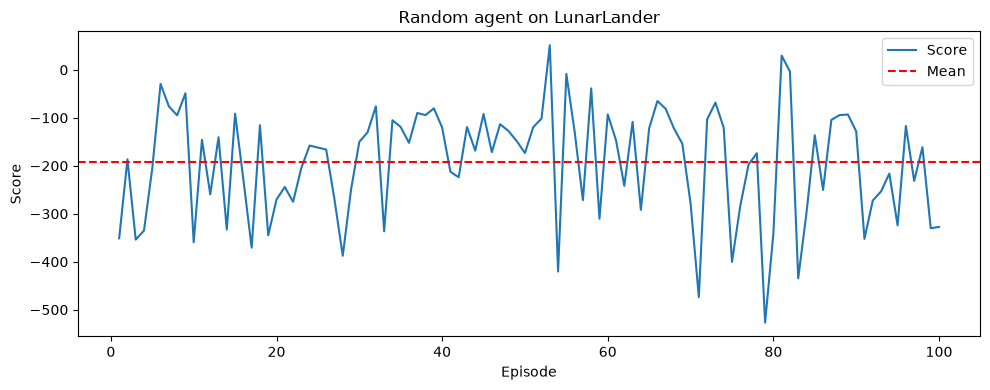

In [5]:
episodes = np.arange(1, len(scores) + 1)

plt.figure(figsize=(10, 4))
plt.plot(episodes, scores, label="Score")
plt.axhline(np.mean(scores), color="red", linestyle="--", label="Mean")
plt.xlabel("Episode")
plt.ylabel("Score")
plt.title("Random agent on LunarLander")
plt.legend()
plt.tight_layout()
plt.show()


## Random agent results

The mean score is -193.03 over 100 episodes, with a standard deviation of 115.39. We get 91 crashes and 9 exits from the screen.

This gives us a starting score. The random agent does not solve the task.

## DQN network

We start with two hidden layers of 64 neurons. This keeps the first network small for an input of 8 state values.

The network returns one Q-value per action. Each value estimates the total reward we can get by taking that action and continuing to play.

ReLU between the layers lets the network learn non-linear relations. The last layer has no activation because Q-values can be negative and are not probabilities.

In [6]:
class DQN(nn.Module):
    def __init__(self, state_size, action_size, hidden_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, action_size),
        )

    def forward(self, state):
        return self.network(state)


q_network = DQN(state_size, action_size, HIDDEN_SIZE)
print(q_network)


DQN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
)


## Checking the output

Let's pass one state as a float32 tensor and check the output. `torch.no_grad()` runs this test without tracking gradients, and `argmax()` gives the action with the highest value.

The weights are still random here. The network has not learned yet.

In [7]:
state_tensor = torch.tensor(state, dtype=torch.float32)

with torch.no_grad():
    q_values = q_network(state_tensor)

best_action = q_values.argmax().item()

print("Input shape:", state_tensor.shape)
print("Output shape:", q_values.shape)
print("Action values:", q_values)
print("Action with the highest value:", best_action)


Input shape: torch.Size([8])
Output shape: torch.Size([4])
Action values: tensor([ 0.0419,  0.1327,  0.0468, -0.0738])
Action with the highest value: 1


## Replay buffer

The buffer stores the state, action, reward, next state and real ending of each step. We keep up to 100,000 experiences to reuse past episodes.

When the buffer is full, new experiences replace the oldest ones. `position` moves to the next slot and goes back to zero at the end.

We will sample batches of 64 experiences at random to mix steps from different episodes. We store `terminated` as the ending flag: a time limit stops the loop but still allows future rewards.

In [8]:
class ReplayBuffer:
    def __init__(self, capacity):
        if capacity < 1:
            raise ValueError("Capacity must be positive")
        self.capacity = capacity
        self.buffer = []
        self.position = 0

    def add(self, state, action, reward, next_state, terminated):
        transition = (state, action, reward, next_state, terminated)
        if len(self.buffer) < self.capacity:
            self.buffer.append(transition)
        else:
            self.buffer[self.position] = transition
        self.position = (self.position + 1) % self.capacity

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, terminateds = zip(*batch)
        return (
            torch.tensor(np.array(states), dtype=torch.float32),
            torch.tensor(actions, dtype=torch.int64),
            torch.tensor(rewards, dtype=torch.float32),
            torch.tensor(np.array(next_states), dtype=torch.float32),
            torch.tensor(terminateds, dtype=torch.float32),
        )

    def __len__(self):
        return len(self.buffer)


## Checking the capacity

Here we put 5 made-up experiences in a buffer with only 3 places. Their rewards go from 0 to 4, so only 2, 3 and 4 should remain.

In [9]:
test_buffer = ReplayBuffer(3)
test_state = np.zeros(state_size, dtype=np.float32)

for reward in range(5):
    test_buffer.add(test_state, 0, reward, test_state, False)

remaining_rewards = sorted(transition[2] for transition in test_buffer.buffer)
print("Stored experiences:", len(test_buffer))
print("Rewards left in the buffer:", remaining_rewards)


Stored experiences: 3
Rewards left in the buffer: [2, 3, 4]


## Filling the buffer

We play one random episode and store each transition. This is just to check that the buffer works with the environment. There is no learning in this loop yet.

In [10]:
replay_buffer = ReplayBuffer(BUFFER_CAPACITY)
env = gym.make("LunarLander-v3", render_mode=None)
state, info = env.reset(seed=SEED)
env.action_space.seed(SEED)
done = False

try:
    while not done:
        action = env.action_space.sample()
        next_state, reward, terminated, truncated, info = env.step(action)
        replay_buffer.add(state, action, reward, next_state, terminated)
        state = next_state
        done = terminated or truncated
finally:
    env.close()

print("Experiences in the replay buffer:", len(replay_buffer))


Experiences in the replay buffer: 123


## Sampling a batch

We check that the buffer has enough experiences before sampling. The states have shape `(batch size, state size)`.

Actions are integers. Rewards, states and ending flags are floats, with 0 or 1 for the flags. These tensors will be used to calculate the DQN loss.

In [11]:
if len(replay_buffer) >= BATCH_SIZE:
    states, actions, rewards, next_states, terminateds = replay_buffer.sample(BATCH_SIZE)

    print("States:", states.shape, states.dtype)
    print("Actions:", actions.shape, actions.dtype)
    print("Rewards:", rewards.shape, rewards.dtype)
    print("Next states:", next_states.shape, next_states.dtype)
    print("Terminations:", terminateds.shape, terminateds.dtype)
else:
    print("Not enough experiences to sample a batch")


States: torch.Size([64, 8]) torch.float32
Actions: torch.Size([64]) torch.int64
Rewards: torch.Size([64]) torch.float32
Next states: torch.Size([64, 8]) torch.float32
Terminations: torch.Size([64]) torch.float32


## Choosing an action

Epsilon is the chance of picking a random action. Otherwise, we take the action with the highest Q-value.

With epsilon at 1, all choices are random. With epsilon at 0, we always follow the network. We will use 0 for evaluation.

For training, epsilon goes from 1 to 0.05 over 100,000 steps. We use a linear decrease because it is easy to follow and leaves more exploration at the start. The minimum keeps a 5% chance of exploring. These are starting values to test during training.

In [12]:
def get_epsilon(step):
    if step >= EPSILON_DECAY_STEPS:
        return EPSILON_END
    decrease = (EPSILON_START - EPSILON_END) * step / EPSILON_DECAY_STEPS
    return EPSILON_START - decrease


def select_action(model, state, epsilon):
    if random.random() < epsilon:
        return random.randrange(action_size)

    state_tensor = torch.tensor(state, dtype=torch.float32)
    with torch.no_grad():
        q_values = model(state_tensor)
    return q_values.argmax().item()


## Checking epsilon

The step counter will cover all training episodes. Here we check the start, middle and end of the decrease, then a later step. Epsilon should stay at 0.05 after 100,000 steps.

In [13]:
test_steps = [0, EPSILON_DECAY_STEPS // 2, EPSILON_DECAY_STEPS, 2 * EPSILON_DECAY_STEPS]

for step in test_steps:
    print(f"Step {step}: epsilon = {get_epsilon(step):.3f}")


Step 0: epsilon = 1.000
Step 50000: epsilon = 0.525
Step 100000: epsilon = 0.050
Step 200000: epsilon = 0.050


## Checking both choices

Here we repeat the choice on the same state. With epsilon at 1, the actions can change. With epsilon at 0, they should match the highest Q-value.

We check that random actions are valid and that the network choice matches `argmax()`. The network is still untrained, so its choice is not a reliable landing strategy yet.

In [14]:
random.seed(SEED)

with torch.no_grad():
    test_values = q_network(torch.tensor(state, dtype=torch.float32))
expected_action = test_values.argmax().item()

random_actions = [select_action(q_network, state, epsilon=1.0) for _ in range(10)]
greedy_actions = [select_action(q_network, state, epsilon=0.0) for _ in range(10)]

print("With epsilon = 1:", random_actions)
print("With epsilon = 0:", greedy_actions)
print("Action with the highest Q-value:", expected_action)

assert all(0 <= action < action_size for action in random_actions)
assert greedy_actions == [expected_action] * 10
print("Both action selection tests passed")


With epsilon = 1: [0, 1, 0, 0, 0, 1, 0, 3, 2, 0]
With epsilon = 0: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Action with the highest Q-value: 0
Both action selection tests passed


## Target network

The target network is a copy of `q_network`. We will use it to estimate future Q-values when we calculate the loss.

Its weights stay fixed between copies. This gives the main network a stable target while it learns. We copy the main weights at the start and every 1,000 learning updates.

We start with a fixed interval so the main network can change for a while before the target follows. We will check this setting during training. The counter here counts weight updates, while epsilon uses environment steps.

In [15]:
target_network = DQN(state_size, action_size, HIDDEN_SIZE)
target_network.load_state_dict(q_network.state_dict())
target_network.eval()
target_network.requires_grad_(False)


def update_target_network(model, target, learning_step):
    if learning_step > 0 and learning_step % TARGET_UPDATE_EVERY == 0:
        target.load_state_dict(model.state_dict())


## Checking the copy

Both networks should start with the same weights. The target is in evaluation mode and does not track gradients for its weights.

In [16]:
same_weights = all(
    torch.equal(main, target)
    for main, target in zip(q_network.parameters(), target_network.parameters())
)
target_has_gradients = any(weight.requires_grad for weight in target_network.parameters())

assert same_weights
assert not target_has_gradients
assert not target_network.training
print("Same weights at the start:", same_weights)
print("Target weights need gradients:", target_has_gradients)


Same weights at the start: True
Target weights need gradients: False


## Checking the update timing

Here we change the main network's last bias just for the test. The target must stay unchanged before the interval, then match the main network at the interval.

We restore the original weights at the end. This is only a copy test, not a learning update.

In [17]:
main_bias = q_network.network[-1].bias
saved_bias = main_bias.detach().clone()
target_bias = target_network.network[-1].bias
target_before = target_bias.detach().clone()

try:
    with torch.no_grad():
        main_bias.add_(1.0)

    update_target_network(q_network, target_network, TARGET_UPDATE_EVERY - 1)
    assert torch.equal(target_bias, target_before)
    print("Target stays fixed before the interval")

    update_target_network(q_network, target_network, TARGET_UPDATE_EVERY)
    assert torch.equal(target_bias, main_bias)
    print("Target matches the main network at the interval")
finally:
    with torch.no_grad():
        main_bias.copy_(saved_bias)
    target_network.load_state_dict(q_network.state_dict())


Target stays fixed before the interval
Target matches the main network at the interval


## Learning target

The target is the reward plus the discounted best value of the next state. Gamma controls how much we count future rewards. We start at 0.99 to keep future rewards important.

A real ending uses only the reward. A time limit keeps the future estimate because the lander could have continued.

For example, a reward of 10 and a next-state value of 20 give a target of 29.8 with gamma at 0.99. If the episode really ended, the target is 10.

In [18]:
def bellman_targets(rewards, next_values, terminateds, gamma):
    return rewards + gamma * next_values * (1 - terminateds)


example_targets = bellman_targets(
    torch.tensor([10.0, 10.0, 10.0]),
    torch.tensor([20.0, 20.0, 20.0]),
    torch.tensor([0.0, 1.0, 0.0]),
    gamma=0.99,
)
assert torch.allclose(example_targets, torch.tensor([29.8, 10.0, 29.8]))
print("Targets for continuing, terminated and time-limited steps:", example_targets)


Targets for continuing, terminated and time-limited steps: tensor([29.8000, 10.0000, 29.8000])


## Training settings

The first 20-episode test checked the code, but its best evaluation mean was only -369.22. Here we give the same network 300,000 environment steps. We finish the current episode when the budget is reached, so the final step count can be a little higher.

We keep batches of 64, a buffer of 100,000 and gamma at 0.99. Adam starts with a learning rate of 0.001. We compare it with 0.0005 using seed 42 and the same budget. The smaller value makes each weight update smaller.

We evaluate every 10,000 steps on 10 fixed episodes and save the best mean. These seeds help us choose a checkpoint. Final tests use other seeds, so the final scores did not choose the saved weights.

The same settings are also trained with seeds 43 and 44. This checks how much the result changes when training starts differently.

## Learning from a batch

We sample 64 experiences and keep the Q-value of each action with `gather()`. The frozen target network gives the next-state values. MSE measures the difference, then Adam updates the main network.

The model, target and buffer are arguments so each run has its own weights and experiences.

In [19]:
def learn_from_buffer(model, target, buffer, optimizer):
    states, actions, rewards, next_states, terminateds = buffer.sample(BATCH_SIZE)
    predictions = model(states).gather(1, actions.unsqueeze(1)).squeeze(1)

    with torch.no_grad():
        next_values = target(next_states).max(dim=1).values
        targets = bellman_targets(rewards, next_values, terminateds, GAMMA)

    loss = nn.functional.mse_loss(predictions, targets)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss.item()


def episode_end_reason(env, state):
    if not env.unwrapped.lander.awake:
        return "at rest"
    if env.unwrapped.game_over:
        return "crash"
    if abs(state[0]) >= 1:
        return "out of bounds"
    return "time limit"

## Evaluation without exploration

We always choose the action with the highest Q-value. This function uses a separate environment and does not change the weights, replay buffer or epsilon counter.

We keep the score, length and ending of each test episode. The model goes back to its previous mode at the end.

In [20]:
def evaluate_model(model, episodes, seed):
    env = gym.make("LunarLander-v3", render_mode=None)
    was_training = model.training
    model.eval()
    results = {"scores": [], "lengths": [], "endings": []}

    try:
        with torch.no_grad():
            for episode in range(episodes):
                state, info = env.reset(seed=seed + episode)
                score = 0.0
                steps = 0
                done = False

                while not done:
                    values = model(torch.tensor(state, dtype=torch.float32))
                    state, reward, terminated, truncated, info = env.step(values.argmax().item())
                    score += reward
                    steps += 1
                    done = terminated or truncated

                results["scores"].append(score)
                results["lengths"].append(steps)
                results["endings"].append(episode_end_reason(env, state))
    finally:
        env.close()
        model.train(was_training)

    return results

## One training run

Each run starts with new weights, an empty buffer and its own seed. We learn at every step once the buffer contains 64 experiences. The target is copied every 1,000 learning updates.

We keep one mean loss per episode to make the curve readable. The result file also keeps all episode scores, lengths, endings and epsilon values. It is updated after each evaluation so we can follow the run.

In [21]:
def train_dqn(seed, learning_rate, name):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    model = DQN(state_size, action_size, HIDDEN_SIZE)
    target = DQN(state_size, action_size, HIDDEN_SIZE)
    target.load_state_dict(model.state_dict())
    target.eval()
    target.requires_grad_(False)
    buffer = ReplayBuffer(BUFFER_CAPACITY)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    results = {
        "seed": seed, "learning_rate": learning_rate, "budget": TRAIN_STEPS,
        "scores": [], "lengths": [], "endings": [], "losses": [], "epsilons": [],
        "eval_steps": [], "eval_means": [], "steps": 0, "updates": 0,
        "best_mean": -float("inf"), "best_step": 0,
    }
    results["settings"] = {
        "hidden_size": HIDDEN_SIZE, "buffer_capacity": BUFFER_CAPACITY,
        "batch_size": BATCH_SIZE, "gamma": GAMMA,
        "epsilon_start": EPSILON_START, "epsilon_end": EPSILON_END,
        "epsilon_decay_steps": EPSILON_DECAY_STEPS,
        "target_update_every": TARGET_UPDATE_EVERY, "train_steps": TRAIN_STEPS,
        "eval_every": EVAL_EVERY, "eval_episodes": EVAL_EPISODES, "eval_seed": EVAL_SEED,
        "environment": "LunarLander-v3", "gymnasium_version": gym.__version__,
        "torch_version": str(torch.__version__), "cpu_threads": torch.get_num_threads(),
    }
    Path("models").mkdir(exist_ok=True)
    Path("results").mkdir(exist_ok=True)
    model_path = Path("models") / f"{name}.pt"
    result_path = Path("results") / f"{name}.json"
    env = gym.make("LunarLander-v3", render_mode=None)
    start = time.perf_counter()
    evaluation_seconds = 0.0
    next_evaluation = EVAL_EVERY

    try:
        while results["steps"] < TRAIN_STEPS:
            state, info = env.reset(seed=seed + len(results["scores"]))
            score = 0.0
            steps = 0
            losses = []
            done = False

            while not done:
                epsilon = get_epsilon(results["steps"])
                action = select_action(model, state, epsilon)
                next_state, reward, terminated, truncated, info = env.step(action)
                buffer.add(state, action, reward, next_state, terminated)
                state = next_state
                score += reward
                steps += 1
                results["steps"] += 1

                if len(buffer) >= BATCH_SIZE:
                    losses.append(learn_from_buffer(model, target, buffer, optimizer))
                    results["updates"] += 1
                    update_target_network(model, target, results["updates"])
                done = terminated or truncated

            results["scores"].append(score)
            results["lengths"].append(steps)
            results["endings"].append(episode_end_reason(env, state))
            results["losses"].append(float(np.mean(losses)) if losses else 0.0)
            results["epsilons"].append(get_epsilon(results["steps"]))

            if results["steps"] >= next_evaluation or results["steps"] >= TRAIN_STEPS:
                evaluation_start = time.perf_counter()
                test = evaluate_model(model, EVAL_EPISODES, EVAL_SEED)
                mean_score = float(np.mean(test["scores"]))
                evaluation_seconds += time.perf_counter() - evaluation_start
                results["eval_steps"].append(results["steps"])
                results["eval_means"].append(mean_score)
                print(f"{name}: step {results['steps']}, evaluation mean = {mean_score:.2f}")

                if mean_score > results["best_mean"]:
                    results["best_mean"] = mean_score
                    results["best_step"] = results["steps"]
                    torch.save({
                        "model_state_dict": model.state_dict(),
                        "state_size": int(state_size), "action_size": int(action_size),
                        "hidden_size": HIDDEN_SIZE, "seed": seed,
                        "learning_rate": learning_rate, "training_steps": results["steps"],
                        "mean_score": mean_score,
                    }, model_path)
                results["run_seconds"] = time.perf_counter() - start
                results["training_seconds"] = results["run_seconds"] - evaluation_seconds
                result_path.write_text(json.dumps(results, indent=2))
                next_evaluation += EVAL_EVERY
    finally:
        env.close()

    assert np.all(np.isfinite(results["losses"]))
    assert all(weight.grad is None for weight in target.parameters())
    return results

## Training with seed 42

This is our first full run. The printed scores come from evaluation without exploration. Intermediate checkpoints stay in the models folder.

The saved results and best weights from each run are included in the repository. By default, we load them to review the notebook quickly. Set `RETRAIN = True` in the settings to run all training again. The final evaluations still run without learning.

In [22]:
def get_run(seed, learning_rate, name):
    if RETRAIN:
        return train_dqn(seed, learning_rate, name)
    print("Loading saved run:", name)
    return json.loads(Path(f"results/{name}.json").read_text())

In [23]:
main_run = get_run(SEED, LEARNING_RATE, "dqn_seed_42")

Loading saved run: dqn_seed_42


## Comparing the learning rate

Only the learning rate changes here, from 0.001 to 0.0005. The seed, network, exploration schedule and step budget stay the same. We compare validation curves before looking at the final test scores.

Loading saved run: dqn_lr_0005


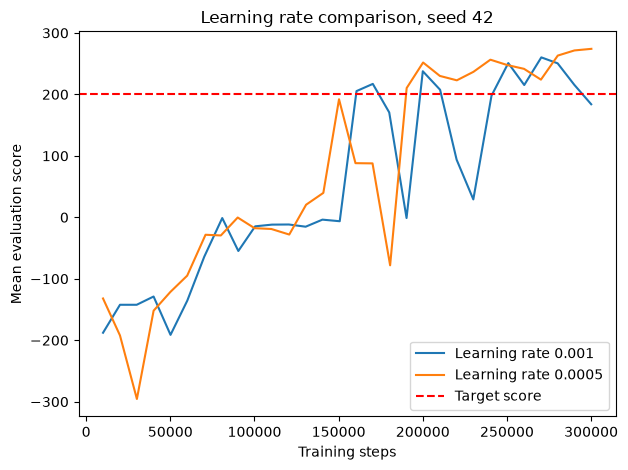

Best validation mean, learning rate 0.001: 260.17
Best validation mean, learning rate 0.0005: 274.05


In [24]:
slower_run = get_run(SEED, 0.0005, "dqn_lr_0005")

for run, label in [(main_run, "Learning rate 0.001"), (slower_run, "Learning rate 0.0005")]:
    plt.plot(run["eval_steps"], run["eval_means"], label=label)
plt.axhline(200, color="red", linestyle="--", label="Target score")
plt.xlabel("Training steps")
plt.ylabel("Mean evaluation score")
plt.title("Learning rate comparison, seed 42")
plt.legend()
plt.tight_layout()
plt.show()
print("Best validation mean, learning rate 0.001:", round(main_run["best_mean"], 2))
print("Best validation mean, learning rate 0.0005:", round(slower_run["best_mean"], 2))

## Two more training seeds

We repeat the original settings with seeds 43 and 44. Each run starts again from random weights. This checks training variation as well as different test situations.

In [25]:
other_runs = []
for seed in TRAIN_SEEDS[1:]:
    other_runs.append(get_run(seed, LEARNING_RATE, f"dqn_seed_{seed}"))
all_runs = [main_run] + other_runs

Loading saved run: dqn_seed_43
Loading saved run: dqn_seed_44


## Training curves

We plot the seed 42 run with the best validation mean in detail. Its moving average uses 50 episodes to reduce the noise. The other plot compares validation scores across all three training seeds.

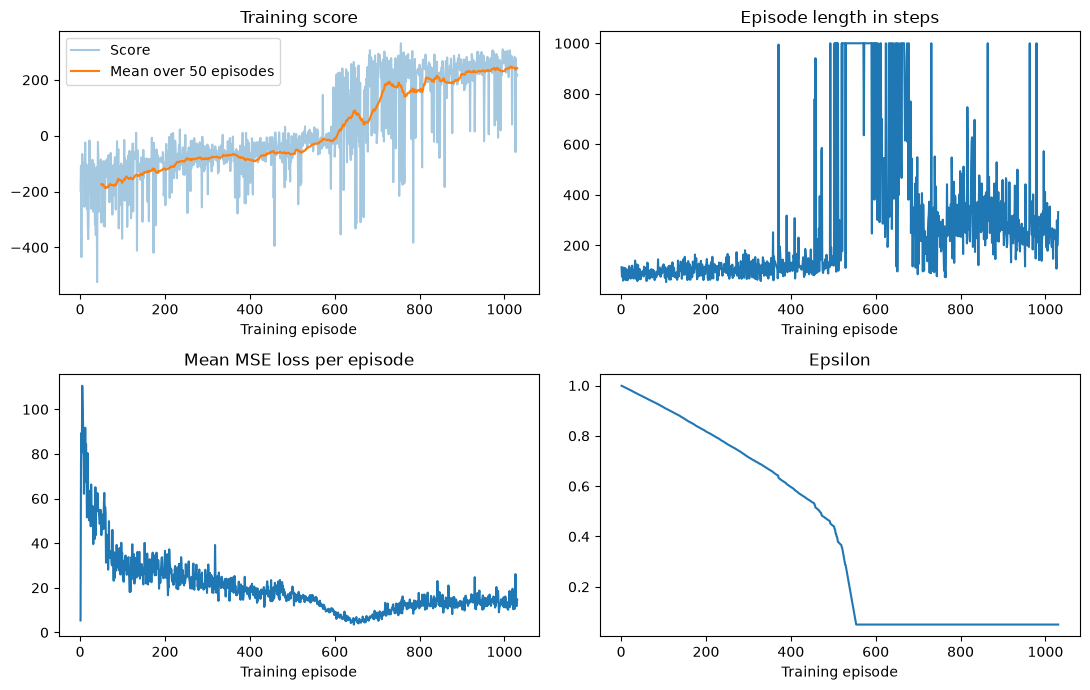

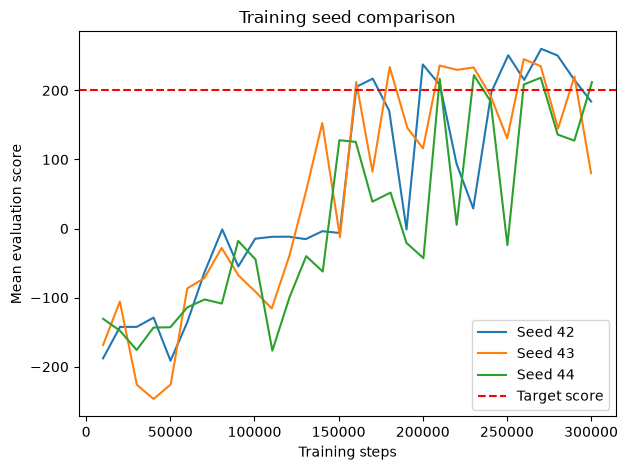

Seed 42: 956 episodes, 300060 steps, 367.1 training seconds
  crash: 536
  out of bounds: 34
  at rest: 288
  time limit: 98
Seed 43: 1047 episodes, 300026 steps, 369.1 training seconds
  crash: 572
  out of bounds: 61
  at rest: 330
  time limit: 84
Seed 44: 954 episodes, 300563 steps, 363.3 training seconds
  crash: 585
  out of bounds: 55
  at rest: 208
  time limit: 106


In [26]:
plot_run = main_run if main_run["best_mean"] >= slower_run["best_mean"] else slower_run
episodes = np.arange(1, len(plot_run["scores"]) + 1)
window = min(50, len(episodes))
moving_average = np.convolve(plot_run["scores"], np.ones(window) / window, mode="valid")

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].plot(episodes, plot_run["scores"], alpha=0.4, label="Score")
axes[0, 0].plot(episodes[window - 1:], moving_average, label="Mean over 50 episodes")
axes[0, 0].set_title("Training score")
axes[0, 0].legend()
axes[0, 1].plot(episodes, plot_run["lengths"])
axes[0, 1].set_title("Episode length in steps")
axes[1, 0].plot(episodes, plot_run["losses"])
axes[1, 0].set_title("Mean MSE loss per episode")
axes[1, 1].plot(episodes, plot_run["epsilons"])
axes[1, 1].set_title("Epsilon")
for ax in axes.flat:
    ax.set_xlabel("Training episode")
plt.tight_layout()
plt.show()

for run in all_runs:
    plt.plot(run["eval_steps"], run["eval_means"], label=f"Seed {run['seed']}")
plt.axhline(200, color="red", linestyle="--", label="Target score")
plt.xlabel("Training steps")
plt.ylabel("Mean evaluation score")
plt.title("Training seed comparison")
plt.legend()
plt.tight_layout()
plt.show()

for run in all_runs:
    print(f"Seed {run['seed']}: {len(run['scores'])} episodes, {run['steps']} steps, "
          f"{run['training_seconds']:.1f} training seconds")
    for reason in ["crash", "out of bounds", "at rest", "time limit"]:
        print(f"  {reason}: {run['endings'].count(reason)}")

## Loading saved weights

We load the network sizes and weights from the checkpoint. The final file comes from the better validation result between the two seed 42 learning rates. Final test scores do not take part in this choice.

In [27]:
def load_dqn(path):
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    model = DQN(checkpoint["state_size"], checkpoint["action_size"], checkpoint["hidden_size"])
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    return model


chosen_name = "dqn_seed_42" if main_run["best_mean"] >= slower_run["best_mean"] else "dqn_lr_0005"
chosen_checkpoint = torch.load(f"models/{chosen_name}.pt", weights_only=True)
torch.save(chosen_checkpoint, "dqn_lunar_lander.pt")
final_model = load_dqn("dqn_lunar_lander.pt")
check = evaluate_model(final_model, EVAL_EPISODES, EVAL_SEED)
assert np.isclose(np.mean(check["scores"]), chosen_checkpoint["mean_score"])
print("Final model:", chosen_name)
print("Saved weights loaded and checked")

Final model: dqn_lr_0005
Saved weights loaded and checked


## Final evaluation

Here we test the saved model on 100 consecutive episodes for each of three seed ranges. There is no exploration or learning. We report the mean, standard deviation, distribution and episode endings.

These seed ranges were not used to select the checkpoint. We also evaluate the best checkpoint from each original training seed over the same 100 test episodes.

In [28]:
final_results = {}
for seed in FINAL_SEEDS:
    test = evaluate_model(final_model, FINAL_EPISODES, seed)
    final_results[str(seed)] = test
    values = np.array(test["scores"])
    print(f"Test seed {seed}: mean = {values.mean():.2f}, std = {values.std():.2f}, "
          f"min = {values.min():.2f}, max = {values.max():.2f}")
    print("Episodes with at least 200 points:", int(np.sum(values >= 200)))
    for reason in ["crash", "out of bounds", "at rest", "time limit"]:
        print(f"  {reason}: {test['endings'].count(reason)}")
Path("results/dqn_final.json").write_text(json.dumps(final_results, indent=2))

seed_results = {}
for run in all_runs:
    seed = run["seed"]
    model = load_dqn(f"models/dqn_seed_{seed}.pt")
    test = evaluate_model(model, FINAL_EPISODES, FINAL_SEEDS[0])
    seed_results[str(seed)] = test
    print(f"Training seed {seed}: mean = {np.mean(test['scores']):.2f}, "
          f"std = {np.std(test['scores']):.2f}")
Path("results/dqn_training_seeds.json").write_text(json.dumps(seed_results, indent=2))

Test seed 20000: mean = 247.55, std = 51.59, min = 14.93, max = 305.12
Episodes with at least 200 points: 89
  crash: 3
  out of bounds: 0
  at rest: 95
  time limit: 2


Test seed 30000: mean = 253.59, std = 56.24, min = -45.48, max = 319.58
Episodes with at least 200 points: 88
  crash: 2
  out of bounds: 0
  at rest: 95
  time limit: 3


Test seed 40000: mean = 253.29, std = 47.46, min = 27.52, max = 308.66
Episodes with at least 200 points: 91
  crash: 2
  out of bounds: 0
  at rest: 94
  time limit: 4


Training seed 42: mean = 220.24, std = 80.69


Training seed 43: mean = 178.68, std = 140.43


Training seed 44: mean = 196.29, std = 80.07


16435

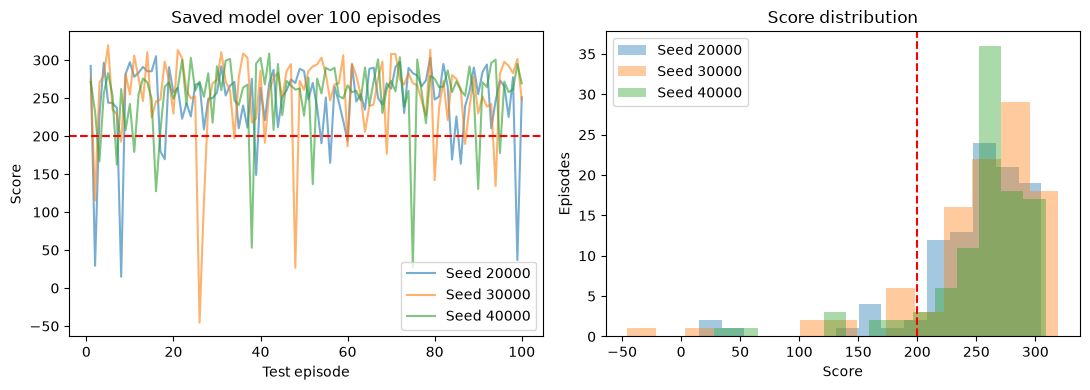

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for seed, test in final_results.items():
    axes[0].plot(np.arange(1, FINAL_EPISODES + 1), test["scores"], alpha=0.6, label=f"Seed {seed}")
    axes[1].hist(test["scores"], bins=15, alpha=0.4, label=f"Seed {seed}")
axes[0].axhline(200, color="red", linestyle="--")
axes[0].set_xlabel("Test episode")
axes[0].set_ylabel("Score")
axes[0].set_title("Saved model over 100 episodes")
axes[1].axvline(200, color="red", linestyle="--")
axes[1].set_xlabel("Score")
axes[1].set_ylabel("Episodes")
axes[1].set_title("Score distribution")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

## Results and conclusion

The final model uses learning rate 0.0005 and training seed 42. Its best validation mean was 274.05 after 300,155 steps, compared with 260.17 for learning rate 0.001. We chose it from validation scores before the final tests.

| Test seed | Episodes | Mean | Standard deviation |
| --- | ---: | ---: | ---: |
| 20000 | 100 | 247.55 | 51.59 |
| 30000 | 100 | 253.59 | 56.24 |
| 40000 | 100 | 253.29 | 47.46 |

The three test means are above 200. There are still some crashes, time limits and scores below 200, so the agent is not perfect. The score distribution shows these failures instead of hiding them.

The smaller learning rate was more stable near the end of this seed 42 run. The comparison is one experiment, so it does not prove that 0.0005 is always better.

| Training seed, learning rate 0.001 | Test mean | Standard deviation |
| --- | ---: | ---: |
| 42 | 220.24 | 80.69 |
| 43 | 178.68 | 140.43 |
| 44 | 196.29 | 80.07 |

The original learning rate gives different results across training seeds. Seeds 43 and 44 stay below the target on this test even though their small validation tests reached it. This shows why we need several seeds and 100 test episodes.

The replay buffer reuses older experiences. The frozen target makes the Bellman target change less often. Epsilon gives the agent time to explore before following its own estimates. All three parts are needed for this training loop.

The first 20-episode model was too weak. More training and the smaller learning rate gave a model that reaches the target on these tests. A next experiment would repeat learning rate 0.0005 with more training seeds.